# SAM 2 for Roman Space Telescope: Tutorial 03
## High-Throughput Fine-Tuning from Paired FITS Directories on NVIDIA A100 (40GB)

This tutorial demonstrates how to train and fine-tune SAM 2 directly from **two separate directories** (paired image and mask FITS files), fully optimized to exploit the massive compute and memory resources of an **NVIDIA A100 GPU with 40GB VRAM** in **Google Colab** (or on AWS / local workstations):

### A100 Hardware Accelerations Enabled:
- **TensorFloat-32 (TF32)**: Accelerates FP32 matrix multiplications up to 10x with zero precision degradation on Ampere Tensor Cores.
- **Native bfloat16 Mixed Precision (AMP)**: Native 16-bit brain floating point for 2x memory reduction and accelerated math.
- **Scaled Batch Size (`batch_size=16` to `32`)**: Fully saturates the A100's 108 Streaming Multiprocessors with multi-object crops.
- **Multi-Worker DataLoader (`num_workers=4`, `pin_memory=True`)**: Exploits the 12 vCPUs and 83.5 GB RAM of Colab High-RAM runtime to feed the A100 asynchronously without GPU starvation.
- **Point Prompts (`prompt_type='point'`)**: Domain-adapts SAM 2 using foreground source clicks.
- **Multi-Mask Crops (`all_masks_in_crop=True`)**: Concurrently trains on all objects present inside each $512 \times 512$ cutout.
- **Default `leakySB` Stretch**: Surface brightness transformation preserving faint galaxy wings with identical RGB channels.

### Google Colab Setup (A100 GPU with 40GB VRAM)

To configure your Google Colab instance for maximum throughput:
1. Go to **Runtime -> Change runtime type**.
2. Under **Hardware accelerator**, select **A100 GPU**.
3. Under **Runtime shape**, select **High-RAM** (giving 12 vCPUs and ~83.5 GB system memory).
4. Run the installation cell below.

In [6]:
## Download the dataset from Google Drive for faster training
import os
if os.path.exists("roman_data"):
    print("Dataset already downloaded.")
else:
    !gdown --id 1AF_zIulNYhq7vvVvD0ZOcVTyxh1xwGM3
    !unzip synthetic_romanisim_sam2.zip -d roman_data

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1AF_zIulNYhq7vvVvD0ZOcVTyxh1xwGM3
From (redirected): https://drive.google.com/uc?id=1AF_zIulNYhq7vvVvD0ZOcVTyxh1xwGM3&confirm=t&uuid=372288ec-c1ea-4c4b-9154-e99fd37e8136
To: /content/sam2roman/synthetic_romanisim_sam2.zip
100% 1.31G/1.31G [00:14<00:00, 91.6MB/s]
Archive:  synthetic_romanisim_sam2.zip
   creating: roman_data/sam2roman_s3/
  inflating: roman_data/sam2roman_s3/.DS_Store  
  inflating: roman_data/__MACOSX/sam2roman_s3/._.DS_Store  
   creating: roman_data/sam2roman_s3/images/
   creating: roman_data/sam2roman_s3/mask /
  inflating: roman_data/sam2roman_s3/images/scene_0001_F106_detector_01.fits  
  inflating: roman_data/__MACOSX/sam2roman_s3/images/._scene_0001_F106_detector_01.fits  
  inflati

In [2]:
# In Google Colab, uncomment and run:
!nvidia-smi
!git clone https://github.com/PabloMSanAla/sam2roman.git
%cd sam2roman
!pip install -e .

# If your Roman synthetic data is stored on Google Drive:
# from google.colab import drive
# drive.mount('/content/drive')
# images_dir = Path('/content/drive/MyDrive/ROMAN/test/synthetic/original')
# masks_dir  = Path('/content/drive/MyDrive/ROMAN/test/synthetic/masks')

Wed Oct 28 22:44:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P0             47W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

### Step 1: Detect Hardware & Configure A100 40GB Optimization Profile

We inspect the available accelerator, enable **TF32** on Ampere Tensor Cores, and automatically set the optimal batch size and worker concurrency based on available VRAM.

In [7]:
import os
import sys
from pathlib import Path

for p in ['/content/sam2roman/src', 'src', '../src', '../../src']:
    resolved = Path(p).resolve()
    if resolved.exists() and str(resolved) not in sys.path:
        sys.path.insert(0, str(resolved))
        break

import matplotlib.pyplot as plt
import numpy as np
import torch

import sam2roman
from sam2roman.training.dataset import AstronomicalDataset
from sam2roman.training.trainer import SAM2Trainer
from sam2roman.inference.segmentor import SAM2Segmentor

print(f"sam2roman version: {sam2roman.__version__}")
print(f"PyTorch version:   {torch.__version__}")

# Hardware detection and A100 resource scaling
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_bytes = torch.cuda.get_device_properties(0).total_memory
    vram_gb = vram_bytes / (1024 ** 3)
    cuda_cap = torch.cuda.get_device_capability(0)
    num_cpus = os.cpu_count() or 4
    
    print(f"\n[Hardware] Accelerator: {gpu_name}")
    print(f"  -> Total VRAM:        {vram_gb:.2f} GB")
    print(f"  -> Compute Cap:       {cuda_cap[0]}.{cuda_cap[1]}")
    print(f"  -> System vCPUs:      {num_cpus}")
    
    # Enable NVIDIA Ampere/Hopper TensorFloat-32 (TF32) for matmuls & cuDNN
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    print("  -> TF32 Tensor Cores: Enabled (allow_tf32=True)")
    print(f"  -> bfloat16 Native:   {'Supported' if torch.cuda.is_bf16_supported() else 'No'}")
    
    # Auto-scale batch size and workers based on available VRAM
    if vram_gb >= 35.0:
        # Full A100 40GB Profile:
        # Batch size 16 processes up to 256 individual source masks concurrently
        BATCH_SIZE = 16
        NUM_WORKERS = min(4, num_cpus)
        PIN_MEMORY = True
        MODEL_ID = "facebook/sam2.1-hiera-tiny"  # Or "facebook/sam2.1-hiera-base-plus" / "large"
        MAX_FILES = None         # Process ALL Roman exposures available!
        EPOCHS = 10
        print(f"\n>> [Profile: A100 40GB High-Throughput] Batch Size: {BATCH_SIZE}, Workers: {NUM_WORKERS}")
    elif vram_gb >= 20.0:
        # L4 / A10G 24GB Profile
        BATCH_SIZE = 8
        NUM_WORKERS = min(2, num_cpus)
        PIN_MEMORY = True
        MODEL_ID = "facebook/sam2.1-hiera-tiny"
        MAX_FILES = None
        EPOCHS = 5
        print(f"\n>> [Profile: 24GB GPU] Batch Size: {BATCH_SIZE}, Workers: {NUM_WORKERS}")
    else:
        # T4 16GB Profile
        BATCH_SIZE = 4
        NUM_WORKERS = min(2, num_cpus)
        PIN_MEMORY = True
        MODEL_ID = "facebook/sam2.1-hiera-tiny"
        MAX_FILES = 4
        EPOCHS = 3
        print(f"\n>> [Profile: 16GB GPU] Batch Size: {BATCH_SIZE}, Workers: {NUM_WORKERS}")
else:
    device_name = "MPS (Apple Silicon)" if torch.backends.mps.is_available() else "CPU"
    print(f"\n[Hardware] Device: {device_name}")
    BATCH_SIZE = 2
    NUM_WORKERS = 0
    PIN_MEMORY = False
    MODEL_ID = "facebook/sam2.1-hiera-tiny"
    MAX_FILES = 4
    EPOCHS = 3
    print(f">> [Profile: Local/MPS] Batch Size: {BATCH_SIZE}, Workers: {NUM_WORKERS}")

# Target directories
images_dir = Path("/Volumes/T7/storage/ROMAN/test/synthetic/original")
masks_dir = Path("/Volumes/T7/storage/ROMAN/test/synthetic/masks")

if not images_dir.exists() or not masks_dir.exists():
    print("\nWarning: External paths not found. Using local sample_data fallback.")
    images_dir = Path("roman_data/sam2roman_s3/images")
    masks_dir = Path("roman_data/sam2roman_s3/masks")

sam2roman version: 0.1.0
PyTorch version:   2.11.0+cu130

[Hardware] Accelerator: NVIDIA A100-SXM4-40GB
  -> Total VRAM:        39.49 GB
  -> Compute Cap:       8.0
  -> System vCPUs:      12
  -> TF32 Tensor Cores: Enabled (allow_tf32=True)
  -> bfloat16 Native:   Supported

>> [Profile: A100 40GB High-Throughput] Batch Size: 16, Workers: 4



### Model Architecture Scaling on A100 (40GB VRAM)

> [!TIP]
> **Scaling to Larger SAM 2 Foundation Models:**
> With 40 GB VRAM, you are not restricted to the lightweight `tiny` model. You can seamlessly select:
> - `facebook/sam2.1-hiera-tiny` (Fastest, ~38.9M params, `BATCH_SIZE=16–32`, uses ~14–22 GB VRAM)
> - `facebook/sam2.1-hiera-base-plus` (Higher accuracy on faint galaxies & crowded stars, `BATCH_SIZE=8–16`, uses ~18–26 GB VRAM)
> - `facebook/sam2.1-hiera-large` (Highest fidelity segmentation, `BATCH_SIZE=4–8`, uses ~22–32 GB VRAM)

### Step 2: Create Dataset from Paired Directories

We use `AstronomicalDataset.from_directories()`. It pairs matching `.fits` files and sets up on-the-fly $512 \times 512$ cutout sampling around sources with point prompts, using the default `leakySB` transformation with identical channels.

In [15]:
! ls roman_data/sam2roman_s3/


images	masks


In [16]:
dataset = AstronomicalDataset.from_directories(
    images_dir=images_dir,
    masks_dir=masks_dir,
    pattern="*.fits",
    crop_size=512,            # Extracts 512x512 windows around objects from 4088x4088 exposures
    prompt_type="point",       # Use POINT prompts (clicks on foreground objects)
    samples_per_file=None,     # None = ALL patches possible (every object across all files!)
    all_masks_in_crop=True,    # Trains on ALL masks present inside each cropped region!
    max_objects_per_crop=16,   # Cap to max 16 objects per crop to bound VRAM
    stretch_type="leakysb",    # Default: leakySB surface brightness stretch with identical channels
    max_samples=MAX_FILES,     # None for all files on A100, or int for subsets
)
print(f"Extracted ALL {len(dataset)} possible multi-object patches across the files!")

# Train (80%) / Validation (20%) split
n_train = max(1, int(0.8 * len(dataset)))
n_val = len(dataset) - n_train
train_ds, val_ds = torch.utils.data.random_split(
    dataset, [n_train, n_val], generator=torch.Generator().manual_seed(42)
)
print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

Extracted ALL 3203 possible multi-object patches across the files!
Train samples: 2562 | Val samples: 641


### Step 3: Inspect a Sample Cutout & Multi-Object Point Prompts

Notice how the point prompts are positioned exactly on target objects in local crop coordinates, rendered with the default `leakySB` stretch.

Cutout contains 6 objects inside this 512x512 crop!


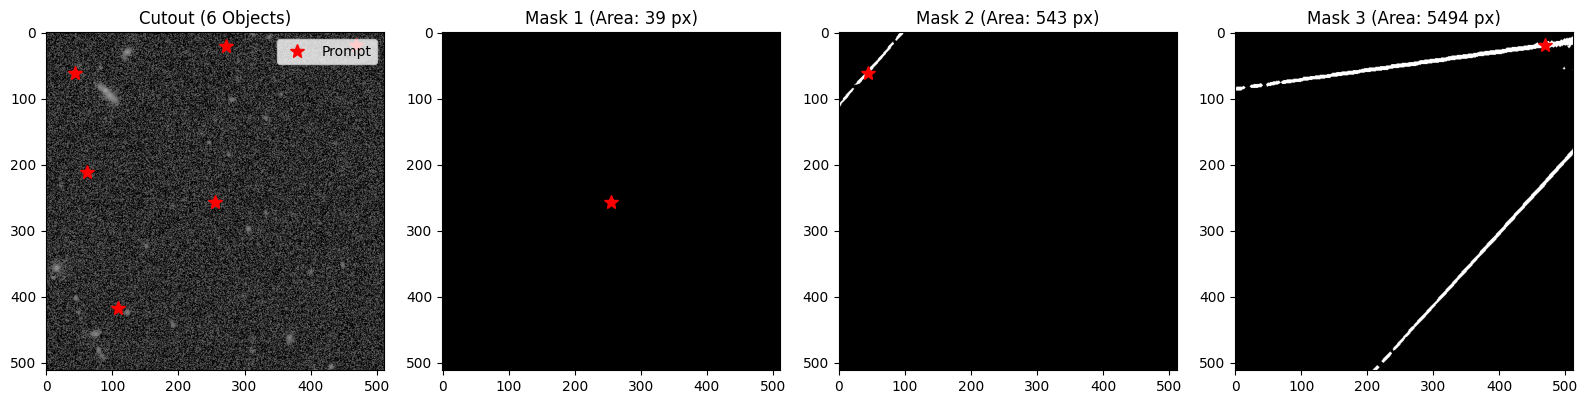

In [17]:
sample = train_ds[0]
img_pil = sample["pil_image"]
num_objs = sample["num_objects"]
points = sample["points"]
masks = sample["masks"]

print(f"Cutout contains {num_objs} objects inside this 512x512 crop!")
n_plots = min(4, 1 + num_objs)
fig, axes = plt.subplots(1, n_plots, figsize=(4 * n_plots, 4))
if n_plots == 1:
    axes = [axes]

axes[0].imshow(img_pil)
for m in range(num_objs):
    pt = points[m, 0].tolist()
    axes[0].plot(pt[0], pt[1], "r*", markersize=10, label="Prompt" if m == 0 else "")
axes[0].set_title(f"Cutout ({num_objs} Objects)")
axes[0].legend(loc="upper right")

for i in range(min(3, num_objs)):
    mask_np = masks[i, 0].numpy()
    pt = points[i, 0].tolist()
    axes[i + 1].imshow(mask_np, cmap="gray")
    axes[i + 1].plot(pt[0], pt[1], "r*", markersize=10)
    axes[i + 1].set_title(f"Mask {i+1} (Area: {int(mask_np.sum())} px)")

plt.tight_layout()
plt.show()

### Step 4: Configure `SAM2Trainer`

We freeze the vision encoder and configure point prompt training with `use_amp=True` (native `bfloat16` on A100).

In [18]:
trainer = SAM2Trainer(
    model_id=MODEL_ID,
    learning_rate=1e-4,
    weight_decay=1e-4,
    freeze_vision_encoder=True,
    prompt_type="point",  # Training with point prompts
    use_amp=True,         # Automatically uses native bfloat16 on A100
)

print(f"Device:               {trainer.device}")
print(f"Trainable parameters: {sum(p.numel() for p in trainer.trainable_params):,}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  156MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

Device:               cuda
Trainable parameters: 4,221,585


### Execute a bash terminal
To follow in real time the efficiency of the training process, you can execute a bash terminal within the notebook.

In [ ]:
import pty
pty.spawn("/bin/bash")

### Step 5: Execute High-Throughput Training Loop

We launch the training loop using the A100-optimized batch size and multi-process DataLoader with pinned memory. Peak VRAM utilization is tracked and reported.

In [19]:
output_dir = Path("checkpoints")
output_dir.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.empty_cache()

history = trainer.train(
    dataset=train_ds,
    val_dataset=val_ds,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    output_dir=output_dir,
    verbose=True,
)

if torch.cuda.is_available():
    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 3)
    curr_vram = torch.cuda.memory_allocated() / (1024 ** 3)
    print(f"\n[A100 Resource Stats]")
    print(f"  -> Peak VRAM Allocated:   {peak_vram:.2f} GB / {vram_gb:.1f} GB ({peak_vram/vram_gb*100:.1f}%)")
    print(f"  -> Current VRAM In-Use:   {curr_vram:.2f} GB")

[sam2roman] Starting fine-tuning for 10 epochs on cuda...
  -> Trainable parameters: 4,221,585
  -> Training crops:       2562 (all masks in crop)
  -> Validation crops:     641 (all masks in crop)
  -> Prompt mode:          point
  -> Batch size:           16
  -> DataLoader:           num_workers=4, pin_memory=True
-----------------------------------------------------------------
Epoch [01/10] - Train Loss: 0.8974 | Val Loss: 0.7335 | Val IoU: 0.1562 (108.2s)
Epoch [02/10] - Train Loss: 0.7046 | Val Loss: 0.6744 | Val IoU: 0.1720 (99.5s)
Epoch [03/10] - Train Loss: 0.6812 | Val Loss: 0.6602 | Val IoU: 0.1835 (100.8s)


KeyboardInterrupt: 

### Step 6: Plot Loss Convergence and Validation IoU

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, len(history["train_loss"]) + 1)

ax1.plot(epochs_range, history["train_loss"], 'o-', label="Train Loss (BCE + Dice)", color="royalblue")
if history["val_loss"]:
    ax1.plot(epochs_range, history["val_loss"], 's--', label="Validation Loss", color="crimson")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Training Convergence")
ax1.grid(True, alpha=0.3)
ax1.legend()

if history["val_iou"]:
    ax2.plot(epochs_range, history["val_iou"], '^-', label="Validation Mean IoU", color="forestgreen")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Mean IoU")
    ax2.set_title("Validation IoU")
    ax2.grid(True, alpha=0.3)
    ax2.legend()

plt.tight_layout()
plt.show()

### Step 7: Test Inference on a Roman Validation Patch with Fine-Tuned Weights

In [ ]:
best_checkpoint = output_dir / "checkpoint_best.pt"
if not best_checkpoint.exists():
    best_checkpoint = output_dir / f"checkpoint_epoch_{EPOCHS}.pt"

# Load fine-tuned weights into segmentor
segmentor = SAM2Segmentor(model_id=MODEL_ID)
segmentor.model_wrapper.model.load_state_dict(
    torch.load(best_checkpoint, map_location=trainer.device)["model_state_dict"]
)
segmentor.model_wrapper.model.eval()
print(f"Loaded fine-tuned model weights from: {best_checkpoint}")

val_sample = val_ds[0]
test_patch = val_sample["raw_data"]
target_pt = val_sample["point"][0].tolist()

res = segmentor.segment_points(
    image=test_patch,
    points=[(target_pt[0], target_pt[1])],
    stretch_type="leakysb",
    verbose=True,
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.imshow(val_sample["pil_image"])
ax1.plot(target_pt[0], target_pt[1], 'r*', markersize=14, label="Input Click Point")
ax1.set_title("Test Patch + Prompt Point")
ax1.legend()

ax2.imshow(val_sample["pil_image"])
if res.masks:
    pred_mask = res.masks[0]
    overlay = np.zeros((*pred_mask.shape, 4))
    overlay[pred_mask] = [0.2, 0.8, 0.2, 0.6]  # Green mask
    ax2.imshow(overlay)
    ax2.set_title(f"Predicted Mask (Area: {res.areas[0]} px, Score: {res.scores[0]:.2f})")

plt.tight_layout()
plt.show()